<a href="https://colab.research.google.com/github/mandapellysameeksha/DEEP-LEARNING/blob/main/skill1_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       VISIONPORT PROJECT
YOLO model loaded successfully!
Ready for real-time object detection


<IPython.core.display.Javascript object>

Camera started successfully!
VisionPort is detecting objects...
Show an object in front of your camera.
Press STOP in Colab to finish detection.


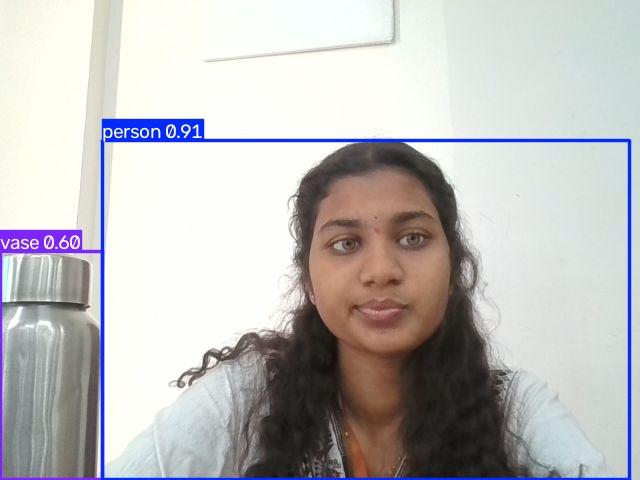

VisionPort detection stopped!
Camera stopped!
VisionPort camera closed successfully!


In [ ]:

# VISIONPORT - REAL TIME OBJECT DETECTION

!pip install -q ultralytics

import cv2
import numpy as np
import base64
import io
import time

from PIL import Image
from IPython.display import display, Javascript, Image as DisplayImage
from google.colab.output import eval_js
from ultralytics import YOLO

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("================================")
print("       VISIONPORT PROJECT")
print("================================")
print("YOLO model loaded successfully!")
print("Ready for real-time object detection")



#CELL 2


# START WEBCAM

display(Javascript("""
async function startVisionPortCamera() {

    const old = document.getElementById('visionport-camera-box');
    if (old) old.remove();

    const video = document.createElement('video');

    video.setAttribute('autoplay', '');
    video.setAttribute('playsinline', '');

    video.style.width = '480px';
    video.style.border = '3px solid green';
    video.style.borderRadius = '10px';

    const stream = await navigator.mediaDevices.getUserMedia({
        video: true
    });

    video.srcObject = stream;
    await video.play();

    const container = document.createElement('div');
    container.id = 'visionport-camera-box';
    container.appendChild(video);

    document.body.appendChild(container);

    window.visionPortVideo = video;
    window.visionPortStream = stream;
    window.visionPortCanvas = document.createElement('canvas');

    return "Camera started successfully!";
}

async function visionPortCaptureFrame() {

    const video = window.visionPortVideo;

    if (!video || video.readyState < 2) {
        return null;
    }

    const canvas = window.visionPortCanvas;

    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;

    canvas.getContext('2d').drawImage(
        video, 0, 0, canvas.width, canvas.height
    );

    return canvas.toDataURL('image/jpeg', 0.8);
}

async function stopVisionPortCamera() {

    if (window.visionPortStream) {
        window.visionPortStream.getTracks().forEach(
            track => track.stop()
        );
    }

    const box = document.getElementById('visionport-camera-box');

    if (box) box.remove();

    return "Camera stopped!";
}
"""))

print(eval_js("startVisionPortCamera()"))


#CELL 3


# REAL-TIME OBJECT DETECTION

display_handle = None

print("VisionPort is detecting objects...")
print("Show an object in front of your camera.")
print("Press STOP in Colab to finish detection.")

try:

    while True:

        # Capture camera frame
        data = eval_js("visionPortCaptureFrame()")

        if data is None:
            continue

        # Convert captured image
        image_bytes = base64.b64decode(data.split(',')[1])

        frame = np.array(
            Image.open(io.BytesIO(image_bytes)).convert("RGB")
        )

        # Convert RGB to BGR for YOLO
        frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)

        # Detect objects using YOLO
        results = model.predict(
            source=frame,
            conf=0.35,
            imgsz=640,
            verbose=False
        )

        # Draw bounding boxes and labels
        result = results[0]

        annotated_frame = result.plot()

        # Convert back to RGB
        annotated_frame = cv2.cvtColor(
            annotated_frame,
            cv2.COLOR_BGR2RGB
        )

        # Display live detection result
        output_image = DisplayImage(
            data=cv2.imencode(
                '.jpg',
                cv2.cvtColor(
                    annotated_frame,
                    cv2.COLOR_RGB2BGR
                )
            )[1].tobytes()
        )

        if display_handle is None:

            display_handle = display(
                output_image,
                display_id=True
            )

        else:

            display_handle.update(output_image)

        time.sleep(0.05)

except KeyboardInterrupt:

    print("VisionPort detection stopped!")


 #CELL 4


print(eval_js("stopVisionPortCamera()"))
print("VisionPort camera closed successfully!")



